# B4 – Konvolusi dan Penapisan Spasial

**SIMUTEH · NIM 2230511115 · SEED 1115**

Notebook ini memuat hitung manual konvolusi, verifikasi korelasi vs konvolusi, perbandingan penapis pada derau Gaussian dan garam-merica, pengaruh kernel median terhadap bercak kecil, serta pengujian PSNR 12 citra normal.

**Lokasi Google Drive:** simpan folder repository ini di `My Drive/Colab Notebooks/simuteh-2230511115/`. Buka notebook dari subfolder `notebook/`. Sel persiapan akan memasang Google Drive di Colab.

> **Catatan Google Colab:** Jalankan sel persiapan terlebih dahulu dan izinkan akses Google Drive. Pastikan folder `simuteh-2230511115` lengkap berada di `Drive Saya/Colab Notebooks/`. Jika sebelumnya pernah menjalankan versi lama, pilih **Runtime → Restart session** lalu jalankan notebook dari atas.

## 4.1 Persiapan

In [1]:
from pathlib import Path
import sys, subprocess, json, time, platform, importlib.metadata
import importlib, re, os

# Pustaka yang digunakan pada praktikum. Google Colab biasanya sudah menyediakannya.
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from IPython.display import display
from time import perf_counter

# 1) Pasang Google Drive bila notebook dijalankan di Google Colab.
try:
    from google.colab import drive
    IN_COLAB = True
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    IN_COLAB = False

# 2) Validasi repository. Folder lama dengan src yang tidak cocok akan dilewati.
DRIVE_NOTEBOOKS = Path('/content/drive/MyDrive/Colab Notebooks')
NIM = '2230511115'
SEED_TARGET = int(NIM[-4:])

_kandidat = [
    DRIVE_NOTEBOOKS / 'simuteh-2230511115',
    DRIVE_NOTEBOOKS / 'simuteh-2230511115' / 'simuteh-2230511115',
    Path.cwd(),
    *Path.cwd().parents,
    Path('/content/simuteh-2230511115'),
]
if DRIVE_NOTEBOOKS.exists():
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*/simuteh-2230511115')))
    _kandidat.extend(sorted(DRIVE_NOTEBOOKS.glob('*')))


def _baca_konstanta_seed(path):
    """Membaca deklarasi SEED sederhana, misalnya: SEED = 1115."""
    if not path.is_file():
        return None
    source = path.read_text(encoding='utf-8-sig')
    cocok = re.search(
        r'(?m)^\s*SEED\s*(?::\s*[^=]+)?=\s*(\d+)\s*(?:#.*)?$',
        source,
    )
    return int(cocok.group(1)) if cocok else None


def _folder_repository(p):
    if not p.is_dir():
        return False
    wajib = [
        p / 'src' / 'buat_dataset_sintetis.py',
        p / 'src' / 'utils_cv.py',
        p / 'src' / 'praproses.py',
        p / 'notebook' / 'B1_lingkungan.ipynb',
        p / 'notebook' / 'B2_citra_warna.ipynb',
        p / 'notebook' / 'B3_histogram.ipynb',
        p / 'notebook' / 'B4_penapisan.ipynb',
        p / 'notebook' / 'B5_praproses.ipynb',
    ]
    if not all(x.is_file() for x in wajib):
        return False
    return _baca_konstanta_seed(p / 'src' / 'buat_dataset_sintetis.py') == SEED_TARGET

ROOT = next((p.resolve() for p in _kandidat if _folder_repository(p)), None)
if ROOT is None:
    raise FileNotFoundError(
        'Repository SIMUTEH versi baru tidak ditemukan atau file src tidak cocok. '
        'Hapus folder simuteh-2230511115 yang lama dari Google Drive, lalu unggah '
        'folder baru hasil ekstraksi ZIP secara utuh ke Drive Saya/Colab Notebooks. '
        'Pastikan src/buat_dataset_sintetis.py memuat baris SEED = 1115.'
    )

SRC = ROOT / 'src'
DATA = ROOT / 'data' / 'sintetis'
CITRA = DATA / 'citra'
BERSIH = DATA / 'bersih'
MASK_DAUN = DATA / 'mask_daun'
MASK_BERCAK = DATA / 'mask_bercak'
HASIL = ROOT / 'hasil'
HASIL.mkdir(parents=True, exist_ok=True)
for _folder in (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK):
    _folder.mkdir(parents=True, exist_ok=True)

# 3) Bersihkan cache impor agar modul yang sudah pernah dipanggil tidak tertukar.
for _nama_modul in ('buat_dataset_sintetis', 'utils_cv', 'praproses'):
    sys.modules.pop(_nama_modul, None)
importlib.invalidate_caches()
_src_text = str(SRC.resolve())
sys.path[:] = [_src_text] + [x for x in sys.path if str(x) != _src_text]

# 4) Pastikan nilai SEED pada skrip sama dengan empat digit terakhir NIM.
SCRIPT_DATASET = SRC / 'buat_dataset_sintetis.py'
SEED = _baca_konstanta_seed(SCRIPT_DATASET)
if SEED != SEED_TARGET:
    raise ValueError(
        f'SEED pada {SCRIPT_DATASET} adalah {SEED}; seharusnya {SEED_TARGET}. '
        'Gunakan folder repository SIMUTEH versi baru.'
    )

# 5) Impor fungsi bantu dari src.
from utils_cv import baca, tampil, kontras_bercak, statistik

# 6) Buat dataset 60 citra bila belum ada atau belum lengkap.
label_path = DATA / 'label.csv'
subfolder_dataset = (CITRA, BERSIH, MASK_DAUN, MASK_BERCAK)
dataset_lengkap = label_path.is_file()
if dataset_lengkap:
    try:
        _cek_label = pd.read_csv(label_path)
        dataset_lengkap = (
            len(_cek_label) == 60
            and _cek_label['nama_file'].nunique() == 60
            and all(sum(1 for _ in folder.glob('teh_*.png')) == 60 for folder in subfolder_dataset)
        )
    except Exception:
        dataset_lengkap = False

if not dataset_lengkap:
    print(f'Dataset belum lengkap. Membuat 60 citra sintetis dengan SEED={SEED} ...')
    subprocess.run([sys.executable, str(SCRIPT_DATASET)], cwd=str(ROOT), check=True)

label = pd.read_csv(label_path)
assert len(label) == 60 and label['nama_file'].nunique() == 60, 'Dataset harus berisi 60 citra unik.'
for _folder in subfolder_dataset:
    _jumlah = sum(1 for _ in _folder.glob('teh_*.png'))
    assert _jumlah == 60, f'Folder {_folder.name} harus berisi 60 gambar, ditemukan {_jumlah}.'

KONDISI = ['normal', 'gelap', 'terang', 'kontras_rendah', 'bayangan']
print('Repository aktif:', ROOT)
print('SEED:', SEED, '| Jumlah citra:', len(label), '| Ukuran citra: 640 x 480')


Mounted at /content/drive
Repository aktif: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115
SEED: 1115 | Jumlah citra: 60 | Ukuran citra: 640 x 480


## 4.2 Hitung manual keluaran filter dan padding

Gunakan matriks P dan Q pada petunjuk. Padding `reflect` yang dimaksud adalah `BORDER_REFLECT_101`.

In [2]:
P = np.array([[52, 55, 61, 58], [59, 255, 64, 60], [62, 60, 0, 57], [58, 61, 59, 63]], dtype=float)
K_mean = np.ones((3, 3), dtype=float) / 9
K_gauss = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=float) / 16

def filter_valid(matriks, kernel, jenis="linear"):
    h, w = matriks.shape; kh, kw = kernel.shape
    out = np.zeros((h-kh+1, w-kw+1), dtype=float)
    for y in range(out.shape[0]):
        for x in range(out.shape[1]):
            area = matriks[y:y+kh, x:x+kw]
            out[y, x] = np.median(area) if jenis == "median" else np.sum(area * kernel)
    return out

hasil_manual = {
    "Rerata 3x3": np.rint(filter_valid(P, K_mean)).astype(int),
    "Gaussian 3x3": np.rint(filter_valid(P, K_gauss)).astype(int),
    "Median 3x3": filter_valid(P, K_mean, "median").astype(int),
}
for nm, out in hasil_manual.items():
    print(nm, "\n", out)

Q = np.array([[70, 72, 75], [74, 120, 78], [73, 76, 79]], dtype=float)
K_sharp = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
hasil_tajam = float(np.sum(Q * K_sharp))
print("Kernel tajam di piksel tengah:", hasil_tajam, "-> setelah clipping:", int(np.clip(hasil_tajam, 0, 255)))

baris = np.array([12, 30, 45, 70], dtype=np.uint8)
padding = {
    "Zero": np.pad(baris, (1, 1), mode="constant", constant_values=0),
    "Replicate": np.pad(baris, (1, 1), mode="edge"),
    "Reflect (BORDER_REFLECT_101)": np.pad(baris, (1, 1), mode="reflect"),
}
for nm, arr in padding.items():
    print(nm, arr.tolist(), "| rerata piksel pertama:", float(arr[:3].mean()))

Rerata 3x3 
 [[74 74]
 [75 75]]
Gaussian 3x3 
 [[104  77]
 [ 77  57]]
Median 3x3 
 [[60 60]
 [60 60]]
Kernel tajam di piksel tengah: 300.0 -> setelah clipping: 255
Zero [0, 12, 30, 45, 70, 0] | rerata piksel pertama: 14.0
Replicate [12, 12, 30, 45, 70, 70] | rerata piksel pertama: 18.0
Reflect (BORDER_REFLECT_101) [30, 12, 30, 45, 70, 45] | rerata piksel pertama: 24.0


## 4.3 Verifikasi korelasi manual, `cv2.filter2D`, dan konvolusi sejati

In [3]:
def korelasi_manual(img_gray, kernel):
    """Korelasi manual tanpa loop piksel; padding tepi memakai replicate.

    sliding_window_view membuat jendela lokal, lalu einsum mengalikan setiap
    jendela dengan kernel. Cara ini tetap memperlihatkan operasi korelasi,
    tetapi jauh lebih cepat dan hemat dibanding dua loop Python pada 640x480.
    """
    from numpy.lib.stride_tricks import sliding_window_view
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Ukuran kernel harus ganjil.")
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img_gray.astype(np.float32), ((ph, ph), (pw, pw)), mode="edge")
    windows = sliding_window_view(pad, (kh, kw))
    out = np.einsum("ijkl,kl->ij", windows, kernel.astype(np.float32), optimize=True)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def konvolusi_sejati(img_gray, kernel):
    """Konvolusi matematis: balik kernel 180 derajat sebelum korelasi."""
    return korelasi_manual(img_gray, np.flip(kernel, axis=(0, 1)))

nama = "teh_041.png"
bersih = baca(BERSIH / nama, gray=True)
md_041 = baca(MASK_DAUN / nama, gray=True)
mb_041 = baca(MASK_BERCAK / nama, gray=True)
kernels = {
    "Rerata simetris": np.ones((3, 3), dtype=float) / 9,
    "Asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], dtype=float),
}
baris_uji = []
for nm, kernel in kernels.items():
    t0 = perf_counter(); manual = korelasi_manual(bersih, kernel); t_manual = perf_counter() - t0
    t0 = perf_counter(); cv = cv2.filter2D(bersih, -1, kernel, borderType=cv2.BORDER_REPLICATE); t_cv = perf_counter() - t0
    sejati = konvolusi_sejati(bersih, kernel)
    baris_uji.append([nm, int(np.abs(manual.astype(int)-cv.astype(int)).max()),
                      int(np.abs(sejati.astype(int)-cv.astype(int)).max()), t_manual, t_cv])
tabel_konvolusi = pd.DataFrame(baris_uji, columns=["Kernel", "Selisih korelasi manual vs filter2D", "Selisih konvolusi sejati vs filter2D", "Waktu manual (s)", "Waktu filter2D (s)"])
display(tabel_konvolusi.round(6))
tabel_konvolusi.to_csv(HASIL / "b4_uji_konvolusi.csv", index=False)

,Kernel,Selisih korelasi manual vs filter2D,Selisih konvolusi sejati vs filter2D,Waktu manual (s),Waktu filter2D (s)
0,Rerata simetris,0,0,0.007221,0.027357
1,Asimetris,0,255,0.001798,0.000348


## 4.4 Bangkitkan derau dan bandingkan enam penapis

Uji derau Gaussian dengan simpangan baku 10, 20, dan 40; serta garam-merica 4% dan 10%. Ukur PSNR terhadap citra bersih, waktu proses, dan KB.

,Derau,Penapis,PSNR (dB),Waktu (ms),KB
0,Gaussian 10,Tanpa,28.106,0.000,4.604
1,Gaussian 10,Rerata 3,36.809,0.122,7.691
2,Gaussian 10,Rerata 5,37.376,0.149,7.771
3,Gaussian 10,Gaussian 5,37.601,0.259,7.894
4,Gaussian 10,Median 3,35.498,0.079,7.601
5,Gaussian 10,Median 5,38.318,0.616,8.757
6,Gaussian 10,Median 9,38.443,13.340,9.752
7,Gaussian 20,Tanpa,22.110,0.000,2.572
8,Gaussian 20,Rerata 3,31.405,0.143,5.873
9,Gaussian 20,Rerata 5,34.348,0.180,6.860


PSNR (dB)                  Waktu (ms)              \
Derau      Garam-merica 4% Gaussian 20 Garam-merica 4% Gaussian 20   
Penapis                                                              
Gaussian 5           29.47       32.53            0.25        0.22   
Median 3             48.47       29.72            0.08        0.10   
Median 5             44.62       33.40            0.58        0.66   
Median 9             40.75       35.47           13.16       12.84   
Rerata 3             28.33       31.40            0.12        0.14   
Rerata 5             31.57       34.35            0.14        0.18   
Tanpa                19.18       22.11            0.00        0.00   

                        KB              
Derau      Garam-merica 4% Gaussian 20  
Penapis                                 
Gaussian 5            5.44        6.30  
Median 3              9.19        5.28  
Median 5              9.33        6.85  
Median 9             10.23        7.81  
Rerata 3              4.90        5.87  
Rerata 5              6.35        6.86  
Tanpa                 1.95        2.57

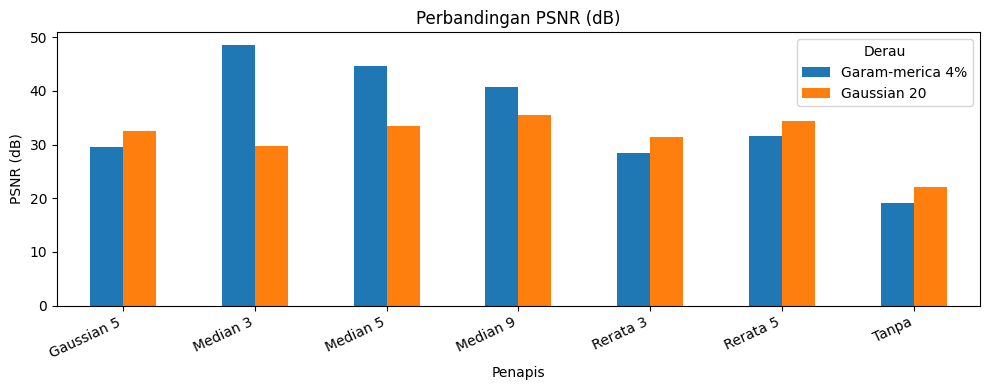

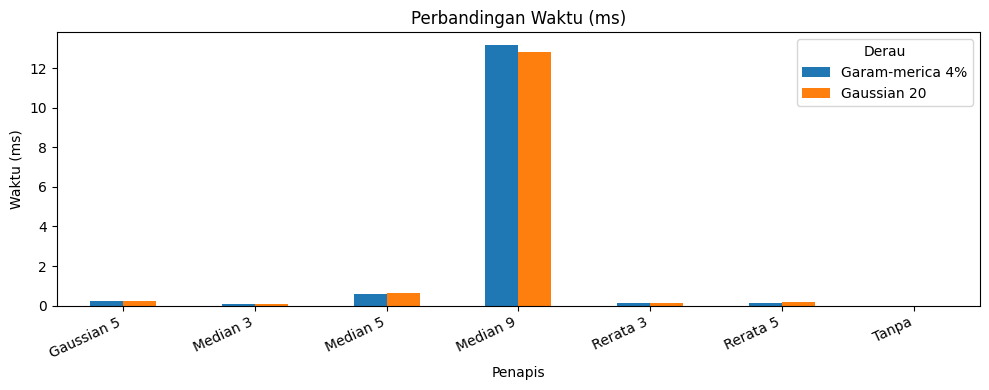

,rank_psnr,rank_kb,rank_waktu,Rata-rata peringkat
Penapis,,,,
Median 3,3.5,4.5,1.0,3.00
Median 9,2.0,1.0,6.0,3.00
Rerata 5,3.0,3.0,3.0,3.00
Median 5,2.5,2.5,5.0,3.33
Gaussian 5,4.5,4.5,4.0,4.33
Rerata 3,5.5,5.5,2.0,4.33


Penapis dengan peringkat gabungan teratas: Median 3


In [4]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img.astype(np.float32) + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, proporsi):
    out = img.copy(); mask = rng.random(img.shape)
    out[mask < proporsi/2] = 0
    out[mask > 1-proporsi/2] = 255
    return out

def ukur_waktu(fungsi, citra, ulang=20):
    hasil_waktu = []
    for _ in range(ulang):
        t0 = perf_counter(); fungsi(citra); hasil_waktu.append(perf_counter()-t0)
    return 1000 * float(np.mean(hasil_waktu))

citra_derau = {
    "Gaussian 10": derau_gauss(bersih, 10),
    "Gaussian 20": derau_gauss(bersih, 20),
    "Gaussian 40": derau_gauss(bersih, 40),
    "Garam-merica 4%": derau_sp(bersih, .04),
    "Garam-merica 10%": derau_sp(bersih, .10),
}
penapis = {
    "Rerata 3": lambda x: cv2.blur(x, (3, 3)),
    "Rerata 5": lambda x: cv2.blur(x, (5, 5)),
    "Gaussian 5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
    "Median 3": lambda x: cv2.medianBlur(x, 3),
    "Median 5": lambda x: cv2.medianBlur(x, 5),
    "Median 9": lambda x: cv2.medianBlur(x, 9),
}
baris_hasil = []
for nama_derau, noisy in citra_derau.items():
    baris_hasil.append([nama_derau, "Tanpa", cv2.PSNR(bersih, noisy), 0.0, kontras_bercak(noisy, md_041, mb_041)])
    for nama_penapis, fungsi in penapis.items():
        out = fungsi(noisy)
        baris_hasil.append([nama_derau, nama_penapis, cv2.PSNR(bersih, out), ukur_waktu(fungsi, noisy), kontras_bercak(out, md_041, mb_041)])
tabel_filter = pd.DataFrame(baris_hasil, columns=["Derau", "Penapis", "PSNR (dB)", "Waktu (ms)", "KB"]).round(3)
display(tabel_filter)
tabel_filter.to_csv(HASIL / "b4_tabel_penapis.csv", index=False)

ringkasan = tabel_filter[tabel_filter["Derau"].isin(["Gaussian 20", "Garam-merica 4%"])]
tabel_11 = ringkasan.pivot(index="Penapis", columns="Derau", values=["PSNR (dB)", "Waktu (ms)", "KB"])
display(tabel_11.round(2))
tabel_11.to_csv(HASIL / "b4_tabel_11_ringkas.csv")
for metrik in ["PSNR (dB)", "Waktu (ms)"]:
    pivot = ringkasan.pivot(index="Penapis", columns="Derau", values=metrik)
    ax = pivot.plot(kind="bar", figsize=(10, 4))
    ax.set_title(f"Perbandingan {metrik}"); ax.set_ylabel(metrik); ax.set_xlabel("Penapis")
    plt.xticks(rotation=25, ha="right"); plt.tight_layout()
    plt.savefig(HASIL / f"b4_grafik_{'psnr' if 'PSNR' in metrik else 'waktu'}.png", dpi=150); plt.show()

# Peringkat gabungan: PSNR dan KB lebih tinggi lebih baik; waktu lebih rendah lebih baik.
rank_data = ringkasan[ringkasan["Penapis"] != "Tanpa"].copy()
for derau in ["Gaussian 20", "Garam-merica 4%"]:
    subset = rank_data[rank_data["Derau"] == derau].copy()
    for metrik, ascending in [("PSNR (dB)", False), ("KB", False), ("Waktu (ms)", True)]:
        rank_data.loc[subset.index, "rank_" + metrik.split()[0].lower()] = subset[metrik].rank(ascending=ascending, method="average")
ringkasan_rank = rank_data.groupby("Penapis")[["rank_psnr", "rank_kb", "rank_waktu"]].mean()
ringkasan_rank["Rata-rata peringkat"] = ringkasan_rank.mean(axis=1)
ringkasan_rank = ringkasan_rank.sort_values("Rata-rata peringkat")
display(ringkasan_rank.round(2))
PENAPIS_KANDIDAT = str(ringkasan_rank.index[0])
print("Penapis dengan peringkat gabungan teratas:", PENAPIS_KANDIDAT)

## 4.5 Pengaruh ukuran median pada bercak kelas ringan

Ukur `dI = |rerata bercak − rerata daun sehat|` dan KB untuk kernel 1 (tanpa filter), 3, 5, 9, dan 15 pada seluruh 20 citra kelas ringan.

,dI,KB
Kernel,,
1,30.43,4.80
3,30.89,4.92
5,29.82,4.80
9,23.34,4.29
15,7.25,1.85


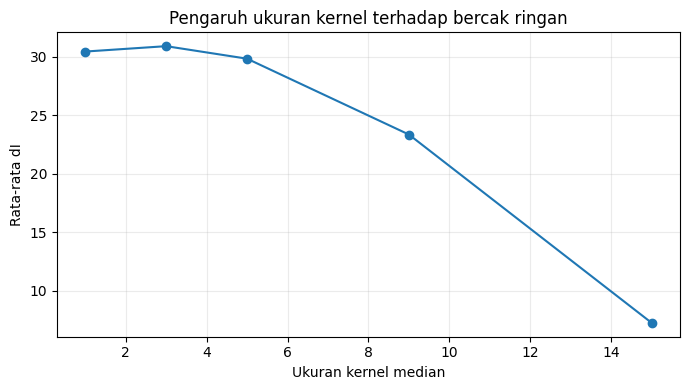

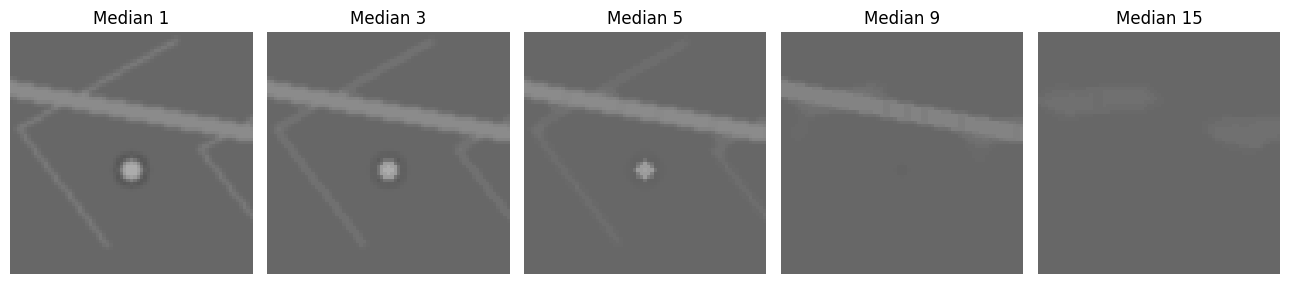

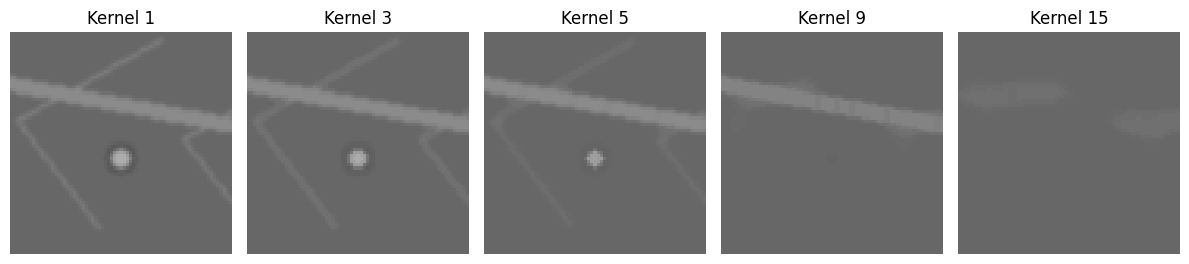

In [5]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    bercak = mask_bercak > 0
    if not bercak.any() or not sehat.any(): return np.nan
    return abs(k[bercak].mean() - k[sehat].mean())

baris_median = []
for nomor in range(21, 41):
    nama_file = f"teh_{nomor:03d}.png"
    g = baca(BERSIH / nama_file, gray=True)
    md0 = baca(MASK_DAUN / nama_file, gray=True)
    mb0 = baca(MASK_BERCAK / nama_file, gray=True)
    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris_median.append([nama_file, k, selisih_rerata(out, md0, mb0), kontras_bercak(out, md0, mb0)])
hasil_median = pd.DataFrame(baris_median, columns=["Citra", "Kernel", "dI", "KB"])
median_rata = hasil_median.groupby("Kernel")[["dI", "KB"]].mean().round(2)
display(median_rata)
hasil_median.to_csv(HASIL / "b4_pengaruh_median_detail.csv", index=False)
median_rata.to_csv(HASIL / "b4_pengaruh_kernel_median.csv")

ax = median_rata["dI"].plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Ukuran kernel median"); ax.set_ylabel("Rata-rata dI"); ax.set_title("Pengaruh ukuran kernel terhadap bercak ringan"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(HASIL / "b4_grafik_dI_kernel.png", dpi=150); plt.show()

nama_crop = "teh_021.png"
g0 = baca(BERSIH / nama_crop, gray=True)
mb0 = baca(MASK_BERCAK / nama_crop, gray=True)
ys, xs = np.where(mb0 > 0)
if len(xs):
    cx, cy = int(xs[0]), int(ys[0])
    x1, x2 = max(0, cx-35), min(g0.shape[1], cx+36)
    y1, y2 = max(0, cy-35), min(g0.shape[0], cy+36)
    potongan = [((g0 if k == 1 else cv2.medianBlur(g0, k))[y1:y2, x1:x2]) for k in [1, 3, 5, 9, 15]]
    tampil(potongan, [f"Median {k}" for k in [1,3,5,9,15]], baris=1, ukuran=(13, 3))
    fig, axes = plt.subplots(1, 5, figsize=(12, 3))
    for ax, crop, k in zip(axes, potongan, [1,3,5,9,15]):
        ax.imshow(crop, cmap="gray", vmin=0, vmax=255); ax.set_title(f"Kernel {k}"); ax.axis("off")
    plt.tight_layout(); plt.savefig(HASIL / "b4_crop_bercak_ringan.png", dpi=150); plt.show()

## 4.6 Urutan meredam derau dan menajamkan

Bandingkan urutan tajam → redam dengan redam → tajam untuk Gaussian dan Median. Catat PSNR serta simpangan baku pada area latar.

In [6]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1+k, blur, -k, 0)

noisy = citra_derau["Gaussian 20"]
latar = md_041 == 0
baris_urutan = []
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                 "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    tajam_lalu_redam = redam(unsharp(noisy))
    redam_lalu_tajam = unsharp(redam(noisy))
    baris_urutan.append([nm, cv2.PSNR(bersih, tajam_lalu_redam), tajam_lalu_redam[latar].std(),
                         cv2.PSNR(bersih, redam_lalu_tajam), redam_lalu_tajam[latar].std()])
tabel_urutan = pd.DataFrame(baris_urutan, columns=["Penapis", "PSNR tajam→redam", "Std latar tajam→redam", "PSNR redam→tajam", "Std latar redam→tajam"]).round(2)
display(tabel_urutan)
tabel_urutan.to_csv(HASIL / "b4_urutan_penajaman.csv", index=False)

,Penapis,PSNR tajam→redam,Std latar tajam→redam,PSNR redam→tajam,Std latar redam→tajam
0,Gaussian,30.37,8.23,30.19,8.53
1,Median,30.12,8.38,31.09,7.51


## 4.7 Uji penapis terpilih pada 12 citra kondisi normal

Pilihan awal di bawah diisi dari hasil peringkat gabungan di atas. Ubah bila hasil dan analisis Anda menunjukkan pilihan lain.

In [7]:
PENAPIS_DIPILIH = "Rerata 5"  # pilihan awal; sesuaikan dengan bukti pada tabel
fungsi_pilihan = penapis[PENAPIS_DIPILIH]
baris_12 = []
for nomor in range(1, 60, 5):
    nama_file = f"teh_{nomor:03d}.png"
    noisy = baca(CITRA / nama_file, gray=True)
    clean = baca(BERSIH / nama_file, gray=True)
    filtered = fungsi_pilihan(noisy)
    baris_12.append([nama_file, cv2.PSNR(clean, noisy), cv2.PSNR(clean, filtered)])
tabel_12_normal = pd.DataFrame(baris_12, columns=["Citra", "PSNR sebelum", "PSNR sesudah"]).round(2)
display(tabel_12_normal)
print("Penapis yang diuji:", PENAPIS_DIPILIH)
print("Rata-rata PSNR sebelum:", round(tabel_12_normal["PSNR sebelum"].mean(), 2))
print("Rata-rata PSNR sesudah:", round(tabel_12_normal["PSNR sesudah"].mean(), 2))
tabel_12_normal.to_csv(HASIL / "b4_psnr_12_citra_normal.csv", index=False)

,Citra,PSNR sebelum,PSNR sesudah
0,teh_001.png,32.32,40.47
1,teh_006.png,29.79,39.02
2,teh_011.png,34.05,40.06
3,teh_016.png,30.94,39.50
4,teh_021.png,31.21,39.61
5,teh_026.png,31.77,40.12
6,teh_031.png,32.06,39.54
7,teh_036.png,32.15,40.16
8,teh_041.png,30.28,38.02
9,teh_046.png,29.25,37.60


Penapis yang diuji: Rerata 5
Rata-rata PSNR sebelum: 31.53
Rata-rata PSNR sesudah: 39.25


## 4.8 Perkiraan jumlah operasi

Untuk kernel 5×5 dibutuhkan 25 perkalian per posisi piksel (perkiraan sederhana, tanpa menghitung penanganan tepi).

In [8]:
operasi_4000 = 4000 * 3000 * 25
operasi_640 = 640 * 480 * 25
print("Foto 4000 x 3000:", f"{operasi_4000:,}", "perkalian")
print("Citra 640 x 480:", f"{operasi_640:,}", "perkalian")
print("Perbandingan beban:", round(operasi_4000 / operasi_640, 2), "kali")

Foto 4000 x 3000: 300,000,000 perkalian
Citra 640 x 480: 7,680,000 perkalian
Perbandingan beban: 39.06 kali


## 4.9 Pertanyaan analisis P4

Jawab di laporan dengan merujuk keluaran: **P4.1** perilaku median pada derau impuls; **P4.2** korelasi vs konvolusi dan `filter2D`; **P4.3** pilihan penapis berdasarkan PSNR, waktu, dan KB; **P4.4** kernel median saat bercak kecil mulai hilang; **P4.5** pengaruh urutan redam/tajam; **P4.6** jumlah operasi dan kebutuhan perangkat; **P4.7** mengapa blur ringan tidak cukup untuk anonimisasi wajah.

**Bukti Bagian 4:** `b4_uji_konvolusi.csv`, `b4_tabel_penapis.csv`, grafik PSNR/waktu, grafik dI, crop bercak, urutan penajaman, dan PSNR 12 citra normal.